# 02 - Data cleaning (Phases 3, 4, 5, 8)
Missing values, type standardisation, outliers and geolocation. Raw files are only read; cleaned tables go to the `dataset/clean dataset/` folder. All logic lives in `src/cleaning.py`, and every step is written to `reports/cleaning_log.xlsx`.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 40, 'display.max_colwidth', 90, 'display.max_rows', 80)
from src.cleaning import run_cleaning, outlier_boxplots
res = run_cleaning()
clean = res['clean']

## Cleaning log - every transformation with its reason and validation result

In [2]:
res['log']

,step,phase,dataset,column,issue_identified,affected_records,cleaning_method,reason,records_removed,records_modified,validation_result
0,1,8 geolocation,geolocation,geolocation_city,"8011 spellings of 5965 cities (accents, case, spacing)",73453,"lower-case, strip accents, collapse whitespace",'são paulo' and 'sao paulo' are the same city; matches the accent-free style of custom...,0,73453,PASS
1,2,8 geolocation,geolocation,geolocation_state,rows whose state disagrees with every other row of the same prefix,8,replace with the prefix's modal state,a postal prefix lies in one state; each conflict is a single stray row against 12-179 ...,0,8,PASS
2,3,2 duplicates,geolocation,(all),exact duplicate rows in the raw file,261831,drop_duplicates(),an identical point repeated carries no extra geographic information,261831,0,PASS
3,4,2 duplicates,geolocation,(all),rows that became identical once city spelling and state were standardised,17840,drop_duplicates() after standardisation,"same prefix, coordinates and state; differed only by accent/spacing",17840,0,PASS
4,5,5 outliers,geolocation,geolocation_lat / geolocation_lng,"coordinates outside Brazil (Europe, Argentina, USA, Philippines)",27,flag (flag_outside_brazil); excluded from the prefix median; row retained,geocoding errors - a Brazilian postal prefix cannot be located abroad; flagged rather ...,0,0,PASS
5,6,5 outliers,geolocation,geolocation_lat / geolocation_lng,points more than 100 km from the median of their own prefix (inside Brazil),697,retain; distance stored in dist_to_prefix_median_km,"the median is robust to these points, so they do not move the representative coordinate",0,0,PASS
6,7,8 geolocation,geo_zip (new reference table),"lat, lng, city, state","many points per postal prefix (median 29, max 1,146) - joining on prefix would multipl...",720492,"aggregate to one row per prefix: median lat/lng of in-Brazil points, modal city, state",median is robust to stray points; one row per prefix makes customer/seller joins stric...,0,0,"PASS: 19015 prefixes, 4 without a valid coordinate, 2094 flagged low-confidence (<3 po..."
7,8,4 types/format,orders,(all string columns),leading/trailing whitespace or empty strings,0,str.strip(); empty string -> missing,whitespace creates false distinct values and broken joins,0,0,PASS
8,9,4 types/format,orders,order_status,validate against the 8 documented statuses,0,lower-case + membership check,categorical consistency,0,0,PASS
9,10,4 types/format,orders,order_purchase_timestamp,timestamp stored as text,99441,"pd.to_datetime(format='%Y-%m-%d %H:%M:%S', errors='coerce')","datetime arithmetic; explicit format so malformed values are detected, not guessed",0,99441,PASS (0 conversion failures)


## Missing values: cause, assessment and treatment

In [3]:
res['missing']['missing_by_column']

,dataset,column,missing_count,missing_pct,reason_for_missingness,assessment,treatment,missing_after_cleaning,values_filled,whitespace_only_values_set_to_missing
0,orders,order_approved_at,160,0.161,141 canceled + 5 created orders were never approved (structural). 14 delivered orders ...,meaningful (146) / minor recording gap (14),Preserve NaT. No imputation; approval-time metrics use non-missing rows.,160,0,0
1,orders,order_delivered_carrier_date,1783,1.793,"Order never handed to a carrier: unavailable 609, canceled 550, invoiced 314, processi...",meaningful,Preserve NaT. No imputation.,1783,0,0
2,orders,order_delivered_customer_date,2965,2.982,"Order not delivered: shipped 1107, canceled 619, unavailable 609, invoiced 314, proces...",meaningful (2957) / problematic (8),Preserve NaT. The 8 delivered-without-date orders are flagged (flag_status_date_confli...,2965,0,0
3,reviews,review_comment_title,87656,88.342,Title is optional and the field was introduced late in the period.,meaningful,Preserve missing; indicator has_comment_title. Review scores kept.,87658,0,2
4,reviews,review_comment_message,58247,58.703,Free-text comment is optional; most customers leave only a score.,meaningful,Preserve missing; indicator has_comment_message. Review scores kept.,58274,0,27
5,products,product_category_name,610,1.851,"610 listings without catalogue metadata (category, name length, description length, ph...",problematic but not recoverable,Label 'unknown' + flag_category_missing. No mode imputation.,0,610,0
6,products,product_name_lenght,610,1.851,Same 610 listings as category.,not recoverable,Preserve missing (nullable integer).,610,0,0
7,products,product_description_lenght,610,1.851,Same 610 listings as category.,not recoverable,Preserve missing (nullable integer).,610,0,0
8,products,product_photos_qty,610,1.851,Same 610 listings as category.,not recoverable,Preserve missing (nullable integer).,610,0,0
9,products,product_weight_g,2,0.006,2 products lack all physical attributes; additionally 4 products have an impossible 0 ...,problematic,Category-median imputation (skewed) + flag_physical_attrs_imputed.,0,2,0


In [4]:
res['missing']['relational_missingness']

,relationship,missing_count,base,reason,treatment,missing_pct
0,customers -> geolocation,279,99441,postal prefix not present in the geolocation file,Keep customer; coordinates stay missing in analytical tables (state/city still availab...,0.281
1,sellers -> geolocation,7,3095,postal prefix not present in the geolocation file,Same as customers.,0.226
2,orders -> order_items,775,99441,unavailable / canceled orders that never had items registered,"Keep order; item metrics are 0 / missing, flagged has_items in the sales table.",0.779
3,orders -> payments,1,99441,one delivered order has no payment record in the extract,Keep order; payment total missing (not 0); item value is still known.,0.001
4,orders -> reviews,768,99441,customer did not answer the satisfaction survey,Keep order; review score missing. Never imputed (it is a typical model target).,0.772


## Outliers: IQR, z-score and percentiles
No outlier is removed. Legitimate extremes are flagged; only impossible values (0 g weight, coordinates outside Brazil) are corrected or excluded from aggregates.

In [5]:
res['outliers']['summary']

,dataset,column,n,mean,median,std,skewness,min,p01,p05,p25,p75,p95,p99,p99_9,max,iqr_lower_fence,iqr_upper_fence,iqr_outliers_low,iqr_outliers_high,iqr_outlier_pct,zscore_gt3,outside_valid_range,decision,rationale,flag_column
0,order_items,price,112650,120.6537,74.9900,183.6339,7.9232,0.8500,9.9900,17.0000,39.9000,134.9000,349.9000,890.0000,2110.0000,6735.0000,-102.6000,277.4000,0,8427,7.481,1966,0,retain + flag,"Top prices are real high-ticket goods (computers, appliances, art); right-skew is the ...",price_outlier_iqr
1,order_items,freight_value,112650,19.9903,16.2600,15.8064,5.6399,0.0000,4.4198,7.7800,13.0800,21.1500,45.1200,84.5200,175.5921,409.6800,0.9750,33.2550,521,11613,10.771,2041,0,retain + flag,High freight tracks heavy/bulky goods and long routes; zero freight is free shipping.,freight_outlier_iqr
2,payments,payment_value,103886,154.1004,100.0000,217.4941,9.2540,0.0000,6.6900,26.1125,56.7900,171.8375,437.6350,1039.9165,2339.2333,13664.0800,-115.7813,344.4088,0,7981,7.682,1803,0,retain + flag,Large payments correspond to multi-item or high-ticket orders and reconcile with item ...,payment_value_outlier_iqr
3,payments,payment_installments,103886,2.8534,1.0000,2.6870,1.6551,1.0000,1.0000,1.0000,1.0000,4.0000,10.0000,10.0000,15.0000,24.0000,-3.5000,8.5000,0,6313,6.077,341,0,retain,1-24 instalments is the normal Brazilian credit-card range.,
4,products,product_weight_g,32951,2276.5331,700.0000,4281.8663,3.6050,2.0000,62.0000,107.0000,300.0000,1900.0000,10850.0000,22537.5000,30000.0000,40425.0000,-2100.0000,4300.0000,0,4551,13.811,961,0,retain + flag (zeros corrected),"Heavy items (furniture, appliances) are legitimate; carrier cap ~30-40 kg explains the...",weight_outlier_iqr
5,products,product_length_cm,32951,30.8150,25.0000,16.9140,1.7505,7.0000,16.0000,16.0000,18.0000,38.0000,65.0000,100.0000,105.0000,105.0000,-12.0000,68.0000,0,1380,4.188,616,0,retain,Bounded by carrier limits (max 105 cm); no impossible values.,
6,products,product_height_cm,32951,16.9375,13.0000,13.6372,2.1402,2.0000,2.0000,3.0000,8.0000,21.0000,44.0000,69.0000,102.0500,105.0000,-11.5000,40.5000,0,1892,5.742,728,0,retain,Bounded by carrier limits (max 105 cm); no impossible values.,
7,products,product_width_cm,32951,23.1967,20.0000,12.0787,1.6710,6.0000,11.0000,11.0000,15.0000,30.0000,47.0000,63.0000,92.0000,118.0000,-7.5000,52.5000,0,912,2.768,574,0,retain,Bounded by carrier limits (max 118 cm); no impossible values.,
8,reviews,review_score,99224,4.0864,5.0000,1.3476,-1.3644,1.0000,1.0000,1.0000,4.0000,5.0000,5.0000,5.0000,5.0000,5.0000,2.5000,6.5000,14575,0,14.689,0,0,retain,Ordinal 1-5 scale; all values valid. IQR 'outliers' here are simply low scores.,
9,geolocation,geolocation_lat,720492,-20.9742,-22.8615,5.9184,1.4626,-36.6054,-30.1199,-29.1642,-23.6018,-19.9161,-7.1615,-2.4445,0.0708,45.0659,-29.1305,-14.3874,37087,91714,17.877,12784,27,"flag invalid, exclude from median","Points outside Brazil are geocoding errors: flagged, kept in the row-level file, exclu...",


In [6]:
res['outliers']['investigation']

,check,value,interpretation
0,Items priced above the IQR fence,8427.000,"8,427 rows cannot all be errors: a long right tail of genuine products"
1,Share of item GMV carried by price outliers (%),35.600,removing them would delete this share of revenue
2,Items where freight exceeds price,4124.000,cheap but heavy/remote shipments - legitimate
3,Spearman correlation freight vs product weight,0.447,"freight rises with weight, i.e. high freight is explained, not erroneous"
4,Top-20 payments reconciling with items+freight within R$1,20.000,the largest payments are real orders
5,Largest single order payment (R$),13664.080,order 03caa2c082116e1d31e67e9ae3700499 with 8 items
6,Products at the maximum weight,1.000,max 40425 g
7,Review scores outside 1-5,0.000,scale is intact
8,Geolocation points outside Brazil,27.000,flagged; excluded from prefix medians
9,Orders delivered more than 60 days after purchase,288.000,extreme but real delivery delays - retained (they drive low review scores)


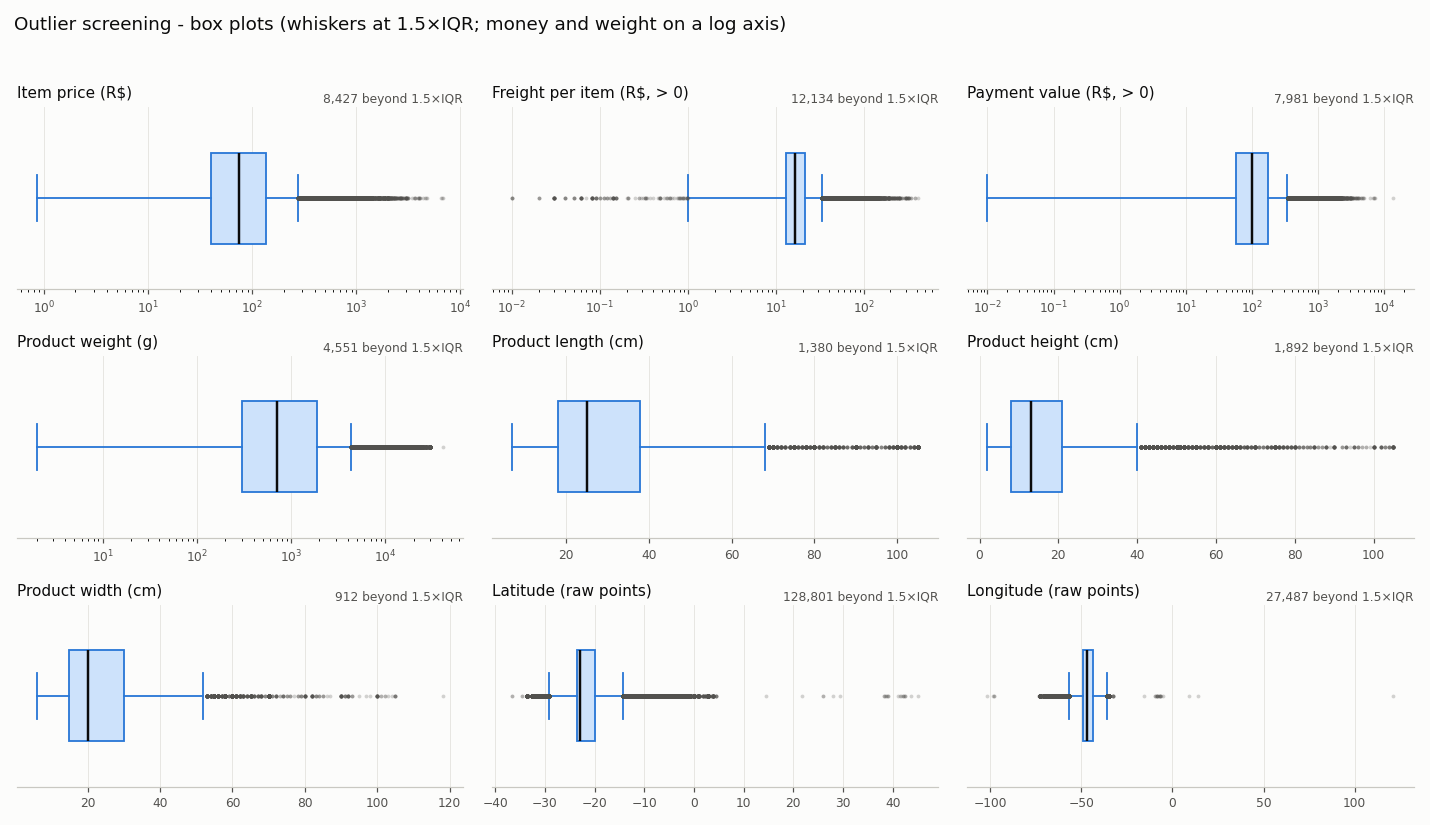

In [7]:
display(Image(outlier_boxplots(clean).getvalue()))

## Postal-prefix reference table (one row per prefix, median coordinate)

In [8]:
clean['geo_zip'].head(10)

,zip_code_prefix,lat,lng,city,state,n_points,n_points_used,n_city_variants,p95_dist_km,max_dist_km,flag_low_confidence
0,01001,-23.550107,-46.634027,sao paulo,SP,10,10,1,0.14,0.15,False
1,01002,-23.548228,-46.635247,sao paulo,SP,6,6,1,0.37,0.45,False
2,01003,-23.548976,-46.635318,sao paulo,SP,10,10,1,0.17,0.19,False
3,01004,-23.549550,-46.634771,sao paulo,SP,14,14,1,0.14,0.15,False
4,01005,-23.549690,-46.636532,sao paulo,SP,11,11,1,0.21,0.22,False
5,01006,-23.550317,-46.636225,sao paulo,SP,7,7,1,0.14,0.14,False
6,01007,-23.550358,-46.637302,sao paulo,SP,15,15,1,0.27,0.30,False
7,01008,-23.545396,-46.635599,sao paulo,SP,12,12,1,0.32,0.33,False
8,01009,-23.546341,-46.636239,sao paulo,SP,7,7,1,0.33,0.33,False
9,01010,-23.546520,-46.635375,sao paulo,SP,5,5,1,0.16,0.16,False


In [9]:
clean['geo_zip'][['n_points', 'n_city_variants', 'p95_dist_km', 'max_dist_km']].describe().round(2)

,n_points,n_city_variants,p95_dist_km,max_dist_km
count,19015.00,19015.00,19011.00,19011.00
mean,37.89,1.03,7.51,13.01
std,50.02,0.19,74.40,96.37
min,1.00,1.00,0.00,0.00
25%,8.00,1.00,0.52,0.60
50%,22.00,1.00,1.02,1.46
75%,48.00,1.00,2.08,5.61
max,746.00,4.00,3024.74,3360.80


## Cleaned tables

In [10]:
pd.DataFrame({k: dict(rows=len(v), columns=v.shape[1], missing_cells=int(v.isna().sum().sum())) for k, v in clean.items()}).T

,rows,columns,missing_cells
geolocation,720492,7,4
geo_zip,19015,11,16
orders,99441,11,4908
order_items,112650,10,0
payments,103886,6,0
reviews,99224,11,145932
customers,99441,5,0
sellers,3095,4,0
category_translation,73,2,0
products,32951,13,1830
